# TA-07: Simulasi Sistem Dinamik Pertumbuhan Logistik
**Studi kasus:** kasus terkonfirmasi kumulatif COVID-19 gelombang Delta di Indonesia (1 Juni - 31 Oktober 2021)

**Nama:** Reyna Noernaila | **NIM:** 301240033 | **Mata kuliah:** Pemodelan dan Simulasi

## Penjelasan model
Stock: $P(t)$ = jumlah kasus kumulatif sejak 1 Juni 2021 (juta jiwa).
Inflow: penularan baru, sebanding dengan $rP$. Feedback penyeimbang: faktor $(1-P/K)$ karena populasi rentan makin berkurang.

$$\frac{dP}{dt} = rP\left(1-\frac{P}{K}\right)$$

Metode Euler: $P_{t+1} = P_t + h\cdot rP_t(1-P_t/K)$

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.grid': True})
URL = "https://raw.githubusercontent.com/datasets/covid-19/main/data/countries-aggregated.csv"
raw = pd.read_csv(URL)
raw.head()

,Date,Country,Confirmed,Recovered,Deaths
0,2020-01-22,Afghanistan,0,0,0
1,2020-01-23,Afghanistan,0,0,0
2,2020-01-24,Afghanistan,0,0,0
3,2020-01-25,Afghanistan,0,0,0
4,2020-01-26,Afghanistan,0,0,0


## 1. EDA singkat

In [2]:
idn = raw[raw['Country'] == 'Indonesia'].copy()
idn['Date'] = pd.to_datetime(idn['Date'])
print("Seluruh data Indonesia:", idn.shape, idn['Date'].min().date(), "s.d.", idn['Date'].max().date())

base = idn.loc[idn['Date'] == '2021-05-31', 'Confirmed'].iloc[0]
w = idn[(idn['Date'] >= '2021-06-01') & (idn['Date'] <= '2021-10-31')].reset_index(drop=True)
df = pd.DataFrame({
    'Time': np.arange(len(w), dtype=float),            # hari ke-0 = 1 Juni 2021
    'Population': (w['Confirmed'].values - base) / 1e6  # juta kasus kumulatif sejak 1 Juni
})
df.to_csv('idn_delta_wave.csv', index=False)
print("Ukuran df:", df.shape)
print(df.dtypes)
print("Missing:", df['Population'].isnull().sum())
print("Monoton naik:", df['Population'].is_monotonic_increasing)
df['Population'].describe()

Seluruh data Indonesia: (816, 5) 2020-01-22 s.d. 2022-04-16
Ukuran df: (153, 2)
Time          float64
Population    float64
dtype: object
Missing: 0
Monoton naik: True


count    153.000000
mean       1.576852
std        0.908543
min        0.004824
25%        0.634209
50%        2.050035
75%        2.379856
max        2.422655
Name: Population, dtype: float64

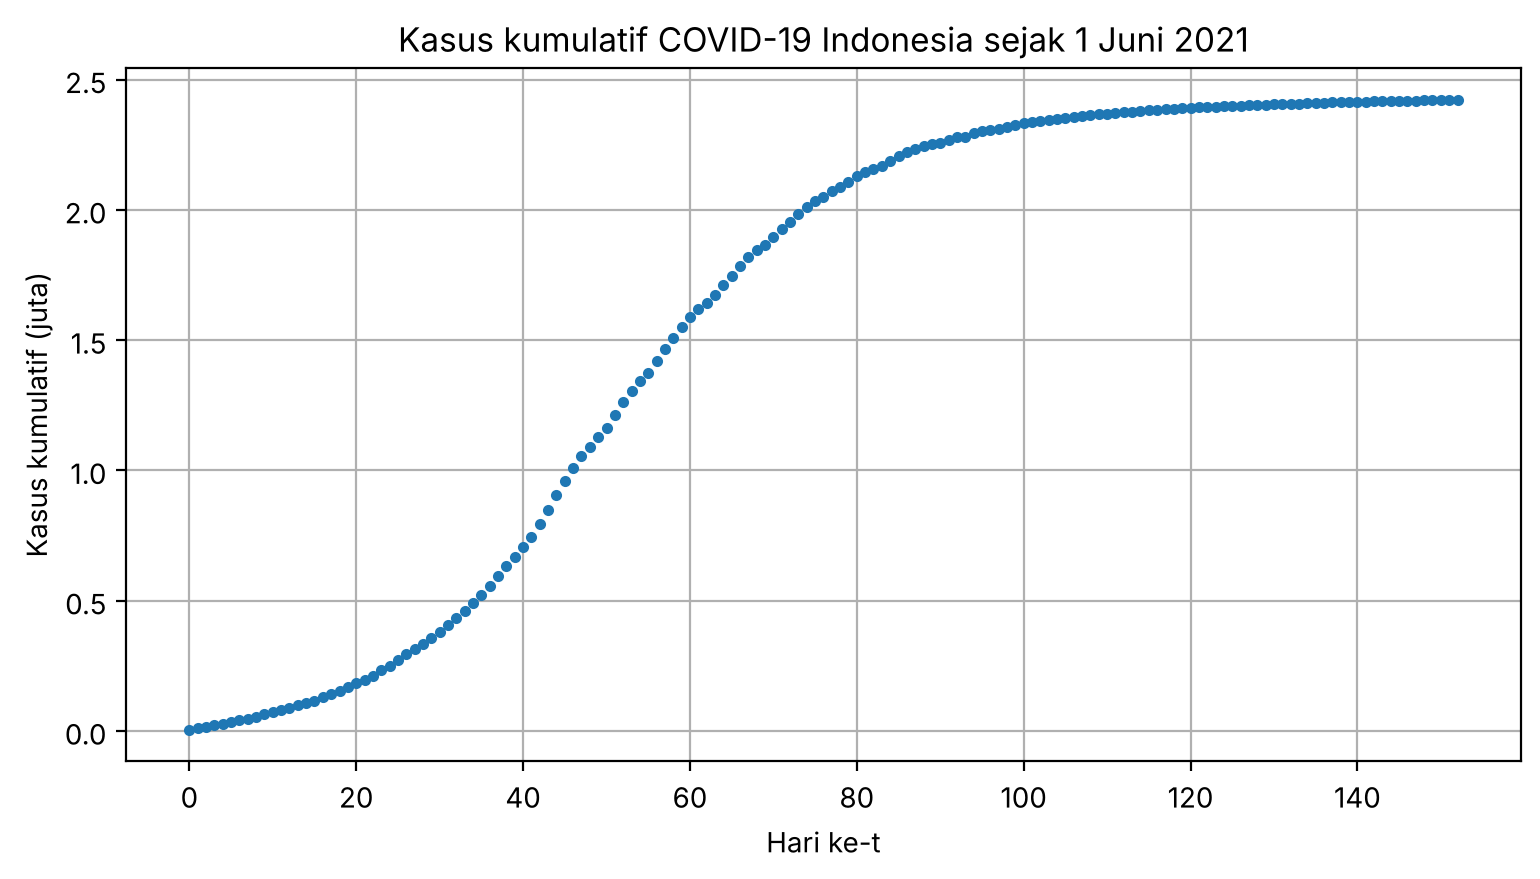

In [3]:
plt.plot(df['Time'], df['Population'], 'o', ms=3)
plt.title("Kasus kumulatif COVID-19 Indonesia sejak 1 Juni 2021")
plt.xlabel("Hari ke-t"); plt.ylabel("Kasus kumulatif (juta)")
plt.savefig('figs/01_data.png', dpi=150, bbox_inches='tight'); plt.show()

## 2. Model dan solver numerik

In [4]:
def f(t, P, r, K):
    return r * P * (1 - P / K)

def euler(f, P0, t0, t1, h, r, K):
    n = int(round((t1 - t0) / h))
    t = t0 + h * np.arange(n + 1)
    P = np.zeros(n + 1); P[0] = P0
    for i in range(n):
        P[i+1] = P[i] + h * f(t[i], P[i], r, K)
    return t, P

def rk4(f, P0, t0, t1, h, r, K):
    n = int(round((t1 - t0) / h))
    t = t0 + h * np.arange(n + 1)
    P = np.zeros(n + 1); P[0] = P0
    for i in range(n):
        k1 = f(t[i], P[i], r, K)
        k2 = f(t[i] + h/2, P[i] + h*k1/2, r, K)
        k3 = f(t[i] + h/2, P[i] + h*k2/2, r, K)
        k4 = f(t[i] + h, P[i] + h*k3, r, K)
        P[i+1] = P[i] + h * (k1 + 2*k2 + 2*k3 + k4) / 6
    return t, P

def metrics(y, yhat):
    rmse = float(np.sqrt(np.mean((y - yhat) ** 2)))
    r2 = float(1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2))
    return rmse, r2

## 3. Kalibrasi parameter r dan K
Solusi analitik logistik dipakai agar `curve_fit` cepat; hasilnya kemudian dipakai oleh Euler, RK4, dan `solve_ivp`.

In [5]:
t = df['Time'].values; y = df['Population'].values; P0 = y[0]; T = t[-1]

def logistic_exact(t, r, K):
    return K / (1 + ((K - P0) / P0) * np.exp(-r * t))

(r_fit, K_fit), _ = curve_fit(logistic_exact, t, y, p0=[0.05, 2.5], maxfev=20000)
print(f"P0 = {P0:.6f} juta | r = {r_fit:.4f} per hari | K = {K_fit:.4f} juta")

P0 = 0.004824 juta | r = 0.1206 per hari | K = 2.3231 juta


## 4. Simulasi dan perbandingan dengan data riil

             RMSE (juta)       R2
Euler (h=1)      0.14485  0.97442
RK4 (h=1)        0.12608  0.98062
solve_ivp        0.12620  0.98058


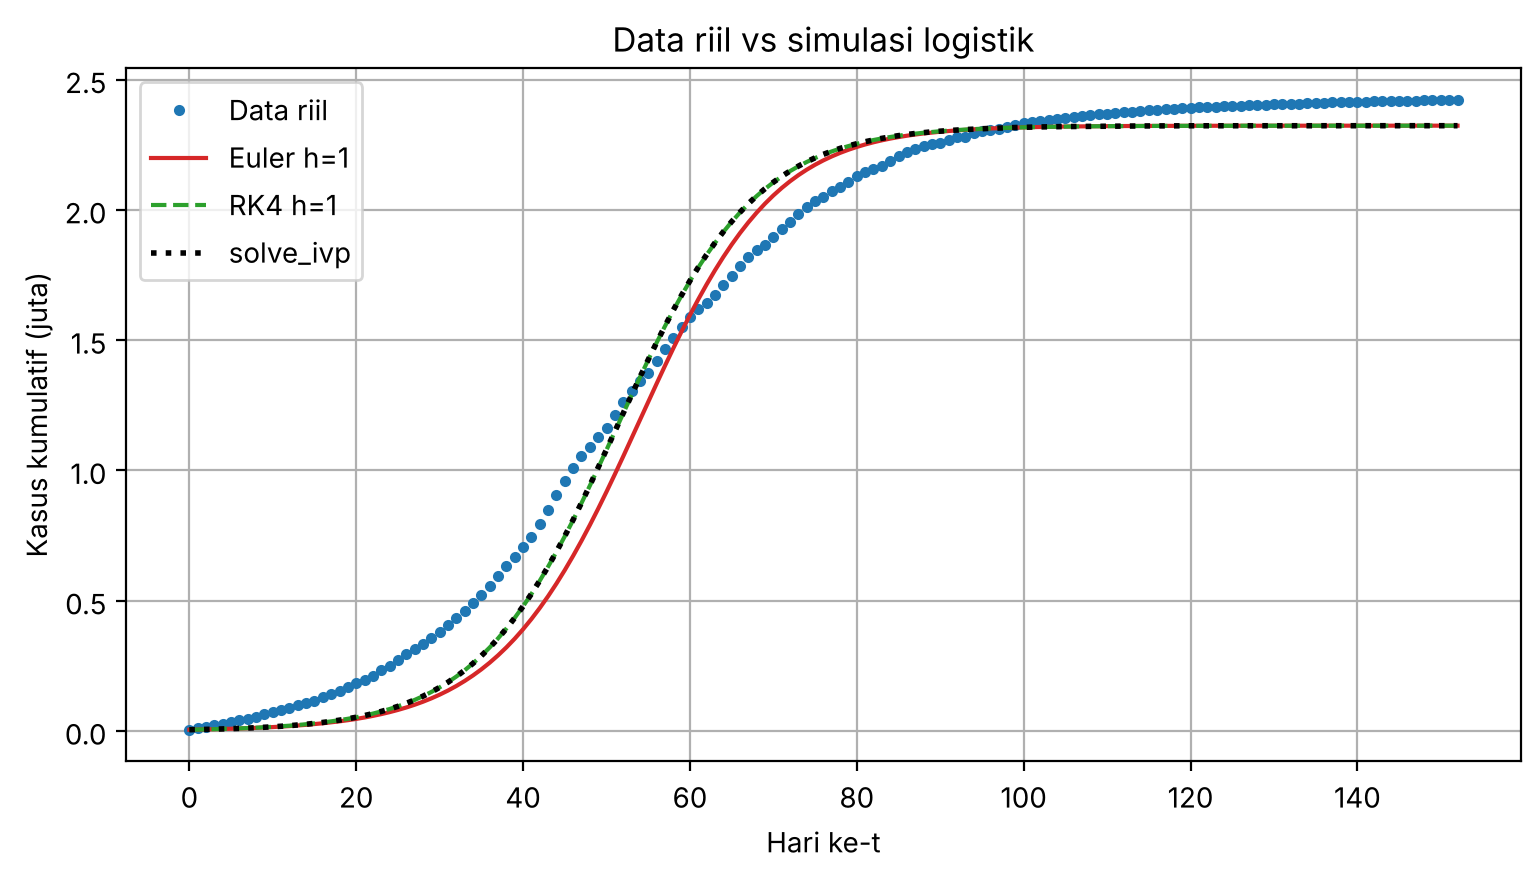

In [6]:
te, Pe = euler(f, P0, 0, T, 1.0, r_fit, K_fit)
tr, Pr = rk4(f, P0, 0, T, 1.0, r_fit, K_fit)
sol = solve_ivp(f, (0, T), [P0], args=(r_fit, K_fit), t_eval=t)

res = {}
for name, yh in [('Euler (h=1)', Pe), ('RK4 (h=1)', Pr), ('solve_ivp', sol.y[0])]:
    res[name] = metrics(y, yh)
print(pd.DataFrame(res, index=['RMSE (juta)', 'R2']).T.round(5))

plt.plot(t, y, 'o', ms=3, label='Data riil', color='tab:blue')
plt.plot(te, Pe, label='Euler h=1', color='tab:red')
plt.plot(tr, Pr, '--', label='RK4 h=1', color='tab:green')
plt.plot(sol.t, sol.y[0], ':', lw=2, label='solve_ivp', color='black')
plt.title("Data riil vs simulasi logistik"); plt.xlabel("Hari ke-t"); plt.ylabel("Kasus kumulatif (juta)")
plt.legend(); plt.savefig('figs/02_sim_vs_data.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Pengaruh step size h pada metode Euler

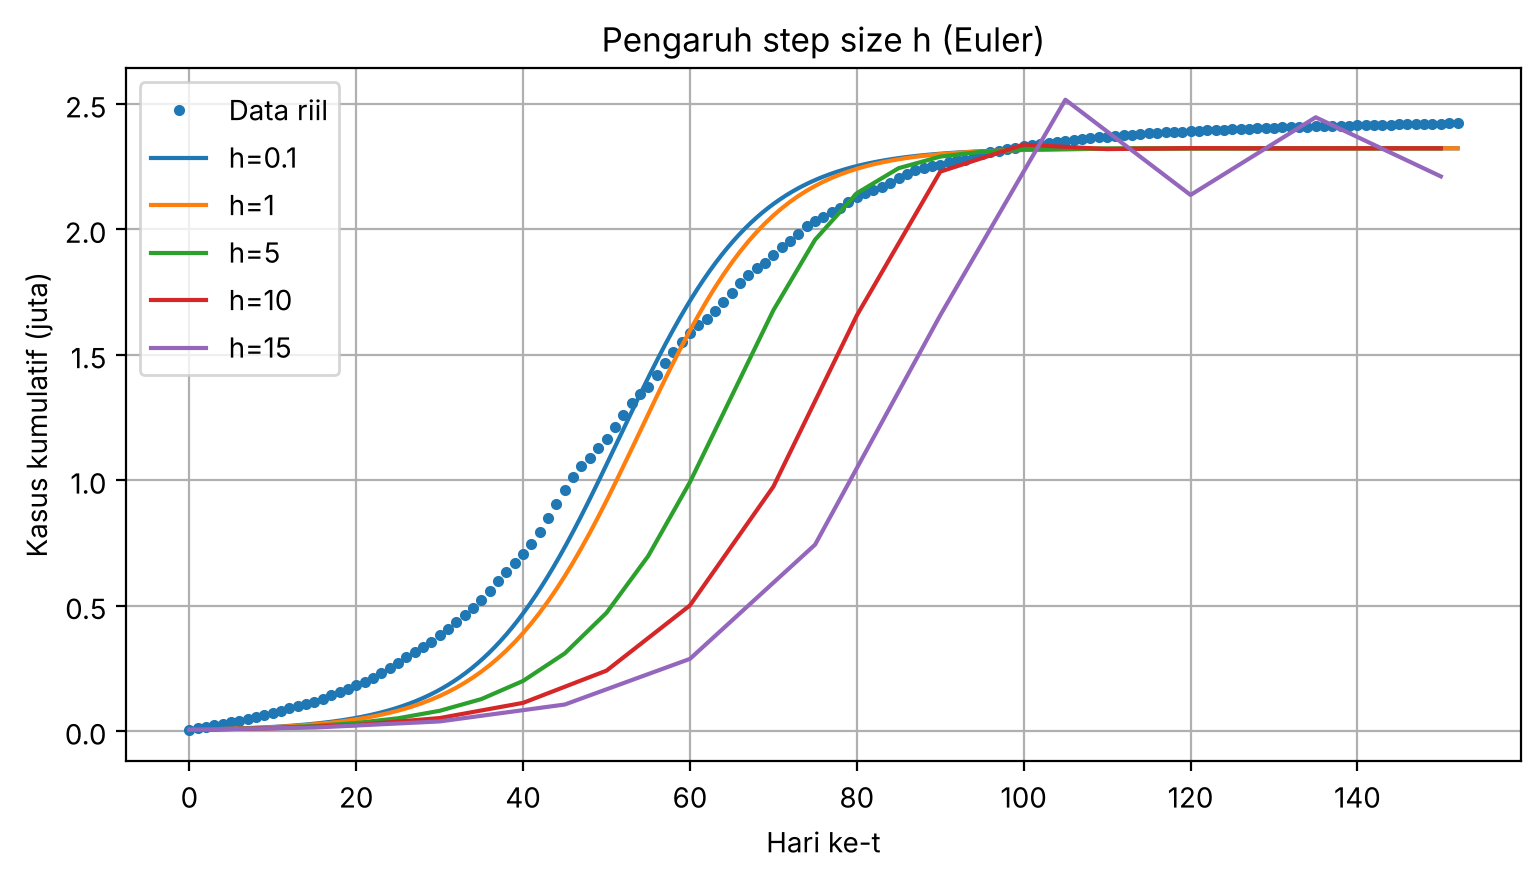

,h (hari),RMSE thd data,R2 thd data,Selisih maks thd referensi
0,0.1,0.12718,0.98028,0.01676
1,1.0,0.14485,0.97442,0.16519
2,5.0,0.29024,0.89728,0.73962
3,10.0,0.48228,0.71636,1.23222
4,15.0,0.65585,0.47548,1.52303


In [7]:
tref, Pref = rk4(f, P0, 0, T, 0.01, r_fit, K_fit)
Pref_t = np.interp(t, tref, Pref)
rows = []
plt.plot(t, y, 'o', ms=3, label='Data riil', color='tab:blue')
for h in [0.1, 1, 5, 10, 15]:
    th, Ph = euler(f, P0, 0, T, h, r_fit, K_fit)
    yh = np.interp(t, th, Ph)
    rmse, r2 = metrics(y, yh)
    rows.append([h, rmse, r2, float(np.max(np.abs(yh - Pref_t)))])
    plt.plot(th, Ph, label=f'h={h}')
plt.title("Pengaruh step size h (Euler)"); plt.xlabel("Hari ke-t"); plt.ylabel("Kasus kumulatif (juta)")
plt.legend(); plt.savefig('figs/03_step_size.png', dpi=150, bbox_inches='tight'); plt.show()
tab_h = pd.DataFrame(rows, columns=['h (hari)', 'RMSE thd data', 'R2 thd data', 'Selisih maks thd referensi']).round(5)
tab_h

## 6. Eksperimen skenario What-If
Baseline vs laju penularan r turun 50% (misal pembatasan mobilitas efektif), r turun 25%, dan kapasitas K turun 30% (misal vaksinasi mengurangi populasi rentan).

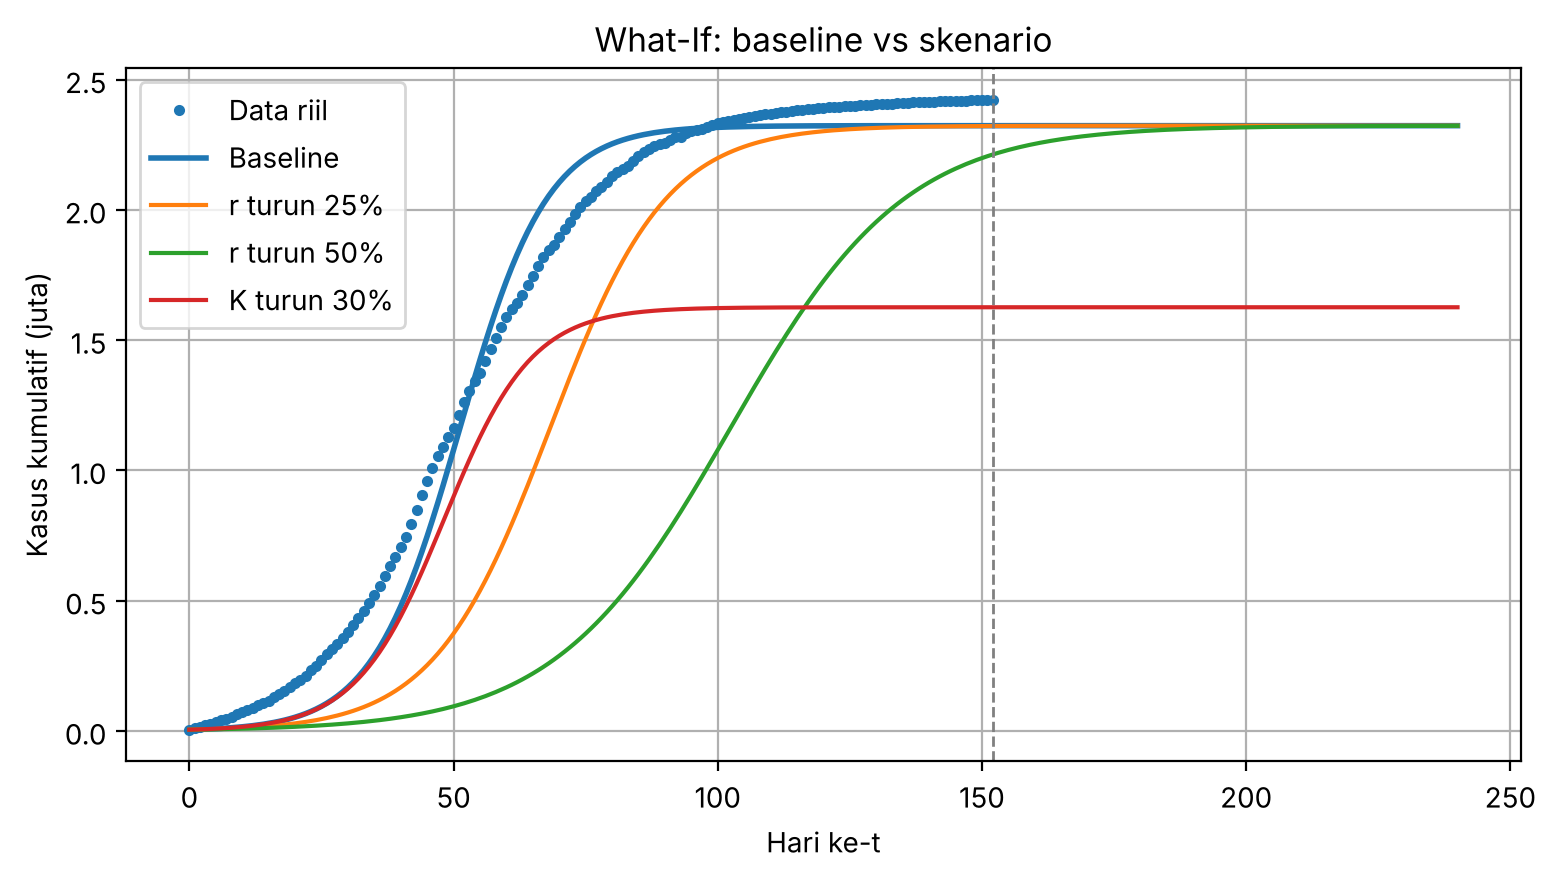

,Skenario,r,K,P hari ke-60 (juta),Hari mencapai 50% K
0,Baseline,0.1206,2.3231,1.7269,51.2
1,r turun 25%,0.0905,2.3231,0.7472,68.2
2,r turun 50%,0.0603,2.3231,0.1674,102.4
3,K turun 30%,0.1206,1.6262,1.3099,48.2


In [8]:
scen = {
    'Baseline': (r_fit, K_fit),
    'r turun 25%': (r_fit * 0.75, K_fit),
    'r turun 50%': (r_fit * 0.50, K_fit),
    'K turun 30%': (r_fit, K_fit * 0.70),
}
T2 = 240  # proyeksi 240 hari agar dampak skenario terlihat
rows = []
plt.plot(t, y, 'o', ms=3, label='Data riil', color='tab:blue')
for name, (r_, K_) in scen.items():
    ts, Ps = rk4(f, P0, 0, T2, 1.0, r_, K_)
    plt.plot(ts, Ps, label=name, lw=2 if name == 'Baseline' else 1.5)
    t50 = float(np.interp(0.5 * K_, Ps, ts))
    rows.append([name, round(r_, 4), round(K_, 4), round(float(np.interp(60, ts, Ps)), 4), round(t50, 1)])
plt.axvline(T, color='gray', ls='--', lw=1)
plt.title("What-If: baseline vs skenario"); plt.xlabel("Hari ke-t"); plt.ylabel("Kasus kumulatif (juta)")
plt.legend(); plt.savefig('figs/04_whatif.png', dpi=150, bbox_inches='tight'); plt.show()
tab_s = pd.DataFrame(rows, columns=['Skenario', 'r', 'K', 'P hari ke-60 (juta)', 'Hari mencapai 50% K'])
tab_s

In [9]:
out = {
    'P0': float(P0), 'r': float(r_fit), 'K': float(K_fit), 'n': int(len(df)), 'base': float(base),
    'p_min': float(df['Population'].min()), 'p_max': float(df['Population'].max()),
    'metrics': {k: list(v) for k, v in res.items()},
    'tab_h': tab_h.values.tolist(), 'tab_s': tab_s.values.tolist(),
}
json.dump(out, open('results.json', 'w'), indent=1)
out

{'P0': 0.004824,
 'r': 0.12064002762242938,
 'K': 2.3231005811965013,
 'n': 153,
 'base': 1821703.0,
 'p_min': 0.004824,
 'p_max': 2.422655,
 'metrics': {'Euler (h=1)': [0.14484705525812303, 0.9744155432745812],
  'RK4 (h=1)': [0.1260817335166811, 0.9806152055054003],
  'solve_ivp': [0.12620453994338265, 0.9805774246683897]},
 'tab_h': [[0.1, 0.12718, 0.98028, 0.01676],
  [1.0, 0.14485, 0.97442, 0.16519],
  [5.0, 0.29024, 0.89728, 0.73962],
  [10.0, 0.48228, 0.71636, 1.23222],
  [15.0, 0.65585, 0.47548, 1.52303]],
 'tab_s': [['Baseline', 0.1206, 2.3231, 1.7269, 51.2],
  ['r turun 25%', 0.0905, 2.3231, 0.7472, 68.2],
  ['r turun 50%', 0.0603, 2.3231, 0.1674, 102.4],
  ['K turun 30%', 0.1206, 1.6262, 1.3099, 48.2]]}

## Interpretasi
- Kurva berbentuk S: tumbuh hampir eksponensial di awal, melambat di tengah, mendatar mendekati K. Ini sesuai struktur feedback: loop penguat (rP) lalu dibatasi loop penyeimbang (1-P/K).
- Euler dengan h=1 hari cukup dekat dengan RK4 dan solve_ivp (selisih maksimum sekitar 0,17 juta); makin besar h, kurva makin meleset dan Euler menjadi tidak stabil bila h mendekati 2/r (sekitar 16 hari).
- Skenario r turun 50% memperlambat dan menunda puncak; K turun 30% menurunkan plateau.
- Keterbatasan: model satu gelombang, parameter konstan, tidak memodelkan perubahan perilaku, vaksinasi, dan pelaporan.